# Exploratory Data Analysis (EDA) - Tiny Instance

This notebook explores and validates the data from the test (*tiny*) instance, covering:
1. File loading and key/integrity validation;
2. Validation of pickup and delivery time-window consistency;
3. Comparison of demand and weight against vehicle capacity;
4. Spatial visualization of the participants on a map.

In [21]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import pandas as pd
from IPython.display import display
from ia26_p01_g19.data_loader import DataLoader

sns.set_theme(style="whitegrid")

loader = DataLoader(data_dir=Path("src") / "data")

vehicles_df = loader.load_vehicles()
orders_df = loader.load_orders()
order_items_df = loader.load_order_items()
producers_df = loader.load_producers()
customers_df = loader.load_customers()
delivery_locations_df = loader.load_delivery_locations()
collection_centers_df = loader.load_collection_centers()
locations_df = loader.load_locations()
localities_df = loader.load_localities()
distance_matrix_df = loader.load_distance_matrix()

print(f"Vehicles: {len(vehicles_df)}")
print(f"Packages: {len(orders_df)} | Ordered Items: {len(order_items_df)}")
print(f"Producers: {len(producers_df)} | Collection Centers: {len(collection_centers_df)}")
print(f"Delivery Locations: {len(delivery_locations_df)}")

Vehicles: 2
Packages: 10 | Ordered Items: 23
Producers: 5 | Collection Centers: 1
Delivery Locations: 6


In [22]:
print("Checking integrity")

# Check whether all order items refer to existing orders
missing_orders = set(order_items_df["order_id"]) - set(orders_df["order_id"])
print(f"Items without an associated order: {len(missing_orders)}")

# Check whether all vehicles have valid collection centers
missing_centers = set(vehicles_df["center_id"]) - set(collection_centers_df["center_id"])
print(f"Vehicles without an associated center: {len(missing_centers)}")

# Check for null values or missing fields in the items
null_counts = order_items_df.isnull().sum()
print("\nNull values in order_items:")
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "No null values detected.")

Checking integrity
Items without an associated order: 0
Vehicles without an associated center: 0

Null values in order_items:
No null values detected.


In [ ]:
print("Time Window Validation")

# Check whether availability_start <= availability_end
invalid_avail = order_items_df[order_items_df["availability_start"] > order_items_df["availability_end"]]
print(f"Items with reversed availability (start > end): {len(invalid_avail)}")

# Check whether delivery_start <= delivery_end
invalid_deliv = order_items_df[order_items_df["delivery_start"] > order_items_df["delivery_end"]]
print(f"Items with reversed delivery window (start > end): {len(invalid_deliv)}")

# Check whether delivery ends before the product is available
impossible_windows = order_items_df[order_items_df["availability_start"] > order_items_df["delivery_end"]]
print(f"Items with an impossible window (pickup starts after delivery ends): {len(impossible_windows)}")

# Calculate the average duration of the windows 
order_items_df["avail_duration_h"] = (
    order_items_df["availability_end"] - order_items_df["availability_start"]
).dt.total_seconds() / 3600.0

order_items_df["deliv_duration_h"] = (
    order_items_df["delivery_end"] - order_items_df["delivery_start"]
).dt.total_seconds() / 3600.0

print(f"Average pickup window duration: {order_items_df['avail_duration_h'].mean():.2f} hours")
print(f"Average delivery window duration: {order_items_df['deliv_duration_h'].mean():.2f} hours")

Time Window Validation
Items with reversed availability (start > end): 0
Items with reversed delivery window (start > end): 0
Items with an impossible window (pickup starts after delivery ends): 0
Average pickup window duration: 3.87 hours
Average delivery window duration: 2.78 hours


 Load VS Capacity
Total order demand / weight: 267.00 kg
Total combined fleet capacity: 2454.50 kg
Maximum weight of a single item: 24.30 kg
Smallest vehicle capacity: 1009.80 kg


C:\Users\laptop-costa\AppData\Local\Temp\ipykernel_4916\1297672633.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vehicles_df, x="vehicle_id", y="capacity_kg", ax=axes[1], palette="crest")


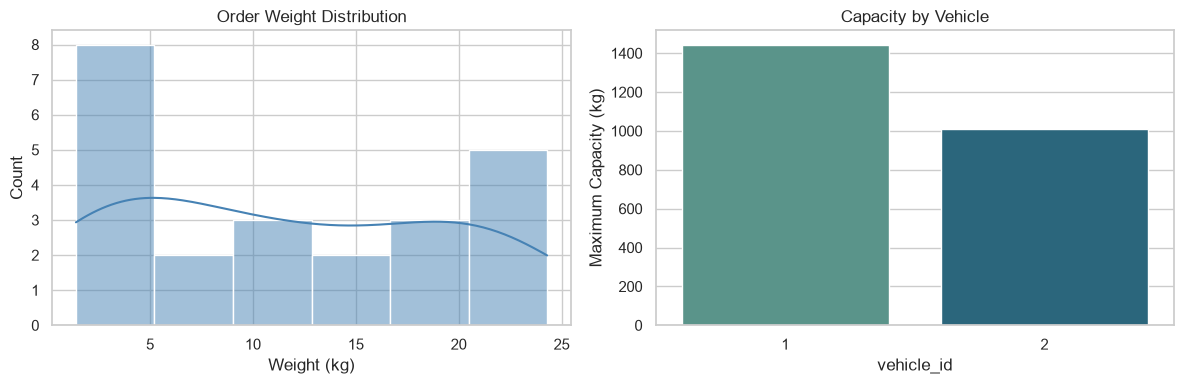

In [ ]:
# Load quantity/weight from the available order-items column
weight_columns = ["weight", "demand", "quantity"]
weight_col = next((column for column in weight_columns if column in order_items_df.columns), None)
if weight_col is None:
    raise KeyError(f"No quantity column found. Expected one of: {weight_columns}")

total_demand = order_items_df[weight_col].sum()
max_item_weight = order_items_df[weight_col].max()
total_vehicle_capacity = vehicles_df["capacity_kg"].sum()
min_vehicle_capacity = vehicles_df["capacity_kg"].min()

print(" Load VS Capacity")
print(f"Total order demand / weight: {total_demand:.2f} kg")
print(f"Total combined fleet capacity: {total_vehicle_capacity:.2f} kg")
print(f"Maximum weight of a single item: {max_item_weight:.2f} kg")
print(f"Smallest vehicle capacity: {min_vehicle_capacity:.2f} kg")

# Graphic
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(order_items_df[weight_col], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Order Weight Distribution")
axes[0].set_xlabel("Weight (kg)")

sns.barplot(data=vehicles_df, x="vehicle_id", y="capacity_kg", ax=axes[1], palette="crest")
axes[1].set_title("Capacity by Vehicle")
axes[1].set_ylabel("Maximum Capacity (kg)")

plt.tight_layout()
plt.show()

In [ ]:
# Add coordinates to each entity using its locality_id
locality_coordinates = localities_df[["locality_id", "latitude", "longitude"]]
centers_map_df = collection_centers_df.merge(locality_coordinates, on="locality_id", how="left")
producers_map_df = producers_df.merge(locality_coordinates, on="locality_id", how="left")
deliveries_map_df = delivery_locations_df.merge(locality_coordinates, on="locality_id", how="left")

stops_map = folium.Map(
    location=[41.5503, -8.4201],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True,
)  

# Add collection centers (red)
for _, row in centers_map_df.dropna(subset=["latitude", "longitude"]).iterrows():
        folium.Marker(
            location=[row["latitude"], row["longitude"]],
            popup=f"Warehouse: {row['center_id']}",
            icon=folium.Icon(color="red", icon="home")
        ).add_to(stops_map)

# Add producers (green)
for _, row in producers_map_df.dropna(subset=["latitude", "longitude"]).iterrows():
        folium.Marker(
            location=[row["latitude"], row["longitude"]],
            popup=f"Producer: {row['producer_id']}",
            icon=folium.Icon(color="green", icon="leaf")
        ).add_to(stops_map)

# Add delivery locations (blue)
for _, row in deliveries_map_df.dropna(subset=["latitude", "longitude"]).iterrows():
        folium.Marker(
            location=[row["latitude"], row["longitude"]],
            popup=f"Delivery: {row['delivery_location_id']}",
            icon=folium.Icon(color="blue", icon="shopping-cart")
        ).add_to(stops_map)

display(stops_map)